### Librerias

In [25]:
import pandas as pd
import numpy as np
import warnings
import time
import matplotlib.pyplot as plt
from IPython.display import display

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### Carga de datos

In [9]:
ruta_archivo = "datosUVR.xlsx"

df = pd.read_excel(
    ruta_archivo,
    sheet_name="Series de datos",
    header=None,
    skiprows=4,
    usecols="A:B"
)

df.columns = ["date", "UVR"]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["UVR"] = pd.to_numeric(df["UVR"], errors="coerce")

df = df.dropna(subset=["date", "UVR"])
fecha_limite = pd.Timestamp("2026-10-31")
df = df[df["date"] <= fecha_limite]
df = df.sort_values("date")
df = (
    df.set_index("date")
      .resample("ME")
      .last()
      .dropna(subset=["UVR"])
      .reset_index()
)

ruta_csv = "UVR_mensual.csv"
df.to_csv(ruta_csv, index=False, date_format="%Y-%m-%d")

print("Datos cargados y procesados correctamente.")
print(f"Dimensiones: {df.shape}")
print(f"Archivo guardado: {ruta_csv}")

print("\nPrimeros registros:")
print(df.head())

print("\nÚltimos registros:")
print(df.tail())

print("\nPeriodo:")
print(f"Desde: {df['date'].min().date()}")
print(f"Hasta: {df['date'].max().date()}")

Datos cargados y procesados correctamente.
Dimensiones: (406, 2)
Archivo guardado: UVR_mensual.csv

Primeros registros:
        date      UVR
0 1993-01-31  31.6330
1 1993-02-28  32.2505
2 1993-03-31  33.3538
3 1993-04-30  34.1925
4 1993-05-31  34.8564

Últimos registros:
          date       UVR
401 2026-06-30  414.7340
402 2026-07-31  416.5435
403 2026-08-31  417.6948
404 2026-09-30  418.8527
405 2026-10-31  420.4693

Periodo:
Desde: 1993-01-31
Hasta: 2026-10-31


In [10]:
faltantes = df.isna().sum()

print("Valores faltantes:")
display(faltantes.to_frame("Valores faltantes"))

print("\nTotal de valores faltantes:", faltantes.sum())

Valores faltantes:


,Valores faltantes
date,0
UVR,0



Total de valores faltantes: 0


### Estadistico descriptivo

In [11]:
estadisticas = df.describe().T

estadisticas

,count,mean,min,25%,50%,75%,max,std
date,406,2009-12-14 22:59:42.266009856,1993-01-31 00:00:00,2001-07-07 18:00:00,2009-12-15 12:00:00,2018-05-23 06:00:00,2026-10-31 00:00:00,NaN
UVR,406.0,191.886699,31.633,119.9835,186.7972,257.96315,420.4693,97.780088


### Serie de tiempo

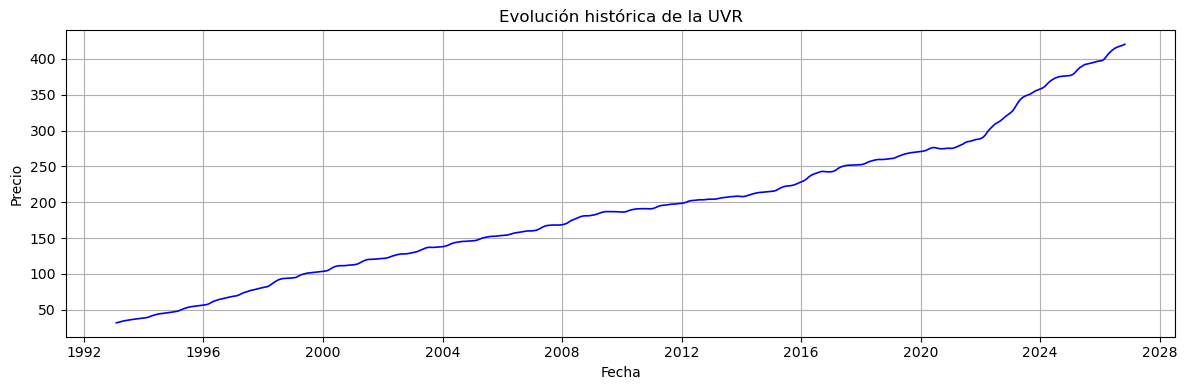

In [12]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["UVR"], color="blue",
    linewidth=1.2)

plt.title(f"Evolución histórica de la UVR")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

### División de datos

In [13]:

df = df.set_index("date").sort_index()
fecha_corte = "2024-10-31"
fecha_inicio_train = "2014-11-01"

train = df.loc[fecha_inicio_train:fecha_corte].copy()
test = df.loc["2024-11-01":].copy()


print("ENTRENAMIENTO")
print(
    train.index.min().date(),
    "-",
    train.index.max().date()
)

print("\nVALIDACIÓN")
print(
    test.index.min().date(),
    "-",
    test.index.max().date()
)

print("\nObservaciones entrenamiento:", len(train))
print("Observaciones validación:", len(test))

ENTRENAMIENTO
2014-11-30 - 2024-10-31

VALIDACIÓN
2024-11-30 - 2026-10-31

Observaciones entrenamiento: 120
Observaciones validación: 24


### Pueba ADF - Estacionariedad

In [14]:
serie = train["UVR"].dropna()

resultado = adfuller(serie)

df_adf = pd.DataFrame([{
    "Variable": "UVR",
    "ADF Statistic": resultado[0],
    "p-value": resultado[1],
    "Estacionaria (5%)": resultado[1] < 0.05
}])

display(df_adf)

,Variable,ADF Statistic,p-value,Estacionaria (5%)
0,UVR,0.518681,0.98543,False


### Prueba de Jung-Box

In [15]:
serie = train["UVR"].dropna()

resultado_lb = acorr_ljungbox(
    serie,
    lags=[5, 10, 15],
    return_df=True
)

display(resultado_lb)

,lb_stat,lb_pvalue
5,515.479673,3.636406e-109
10,880.960855,7.965790e-183
15,1120.045663,2.406800e-229


### Escoger modelo ARIMA

In [16]:
def obtener_d_optimo(serie, max_d=2, alpha=0.05):
    serie_actual = serie.dropna().copy()

    for d in range(max_d + 1):
        p_value = adfuller(serie_actual)[1]

        if p_value < alpha:
            return d

        serie_actual = serie_actual.diff().dropna()

    return max_d


# Calcular d óptimo para la UVR
d_optimo = obtener_d_optimo(train["UVR"])

# Mostrar resultados
df_d = pd.DataFrame([{
    "Variable": "UVR",
    "d óptimo": d_optimo
}])

display(df_d)

,Variable,d óptimo
0,UVR,2


In [17]:
def optimizar_arima(
    serie,
    d,
    max_p=5,
    max_q=5,
    alpha=0.05
):
    mejor_aic = np.inf
    mejor_bic = np.inf
    mejor_orden = None
    mejor_modelo = None

    candidatos = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):

            try:
                modelo = ARIMA(
                    serie,
                    order=(p, d, q)
                )

                resultado = modelo.fit()

                pvalues = resultado.pvalues
                parametros = pvalues
                significativos = (
                    len(parametros) > 0
                    and (parametros < alpha).all()
                )

                candidatos.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": resultado.aic,
                    "BIC": resultado.bic,
                    "Todos significativos": significativos,
                    "Máximo valor p": (
                        parametros.max()
                        if len(parametros) > 0
                        else np.nan
                    )
                })

                if significativos and resultado.aic < mejor_aic:
                    mejor_aic = resultado.aic
                    mejor_bic = resultado.bic
                    mejor_orden = (p, d, q)
                    mejor_modelo = resultado

            except Exception:
                continue

    tabla_candidatos = pd.DataFrame(candidatos)

    if not tabla_candidatos.empty:
        tabla_candidatos = (
            tabla_candidatos
            .sort_values("AIC")
            .reset_index(drop=True)
        )

    return (
        mejor_orden,
        mejor_aic,
        mejor_bic,
        mejor_modelo,
        tabla_candidatos
    )


modelos_arima = {}
tablas_candidatos = {}
resultados_modelos = []

inicio = time.perf_counter()

activo = "UVR"

print(f"Optimizando {activo}...")

serie = train[activo].dropna()

d = int(
    df_d.loc[
        df_d["Variable"] == activo,
        "d óptimo"
    ].iloc[0]
)

(
    mejor_orden,
    mejor_aic,
    mejor_bic,
    mejor_modelo,
    tabla_candidatos
) = optimizar_arima(
    serie,
    d=d,
    max_p=5,
    max_q=5,
    alpha=0.05
)

tablas_candidatos[activo] = tabla_candidatos

if mejor_orden is not None:

    modelos_arima[activo] = mejor_modelo

    resultados_modelos.append({
        "Variable": activo,
        "p": mejor_orden[0],
        "d": mejor_orden[1],
        "q": mejor_orden[2],
        "Orden": mejor_orden,
        "AIC": mejor_aic,
        "BIC": mejor_bic
    })

    print(f"\nMejor modelo: ARIMA{mejor_orden}")
    print(f"AIC: {mejor_aic:.4f}")
    print(f"BIC: {mejor_bic:.4f}")

    print("\nValores p de los parámetros:")
    display(
        pd.DataFrame({
            "Parámetro": mejor_modelo.pvalues.index,
            "Valor p": mejor_modelo.pvalues.values
        })
    )

else:
    print(
        "\nNo se encontró ningún modelo en la búsqueda "
        "en el que todos los parámetros evaluados "
        "sean significativos al 5 %."
    )

tiempo_modelos = time.perf_counter() - inicio

print(
    f"\nOptimización terminada en "
    f"{tiempo_modelos / 60:.2f} minutos."
)


df_resultados_arima = pd.DataFrame(resultados_modelos)

print("\nModelo seleccionado:")
display(df_resultados_arima)

print("\nCandidatos con todos los parámetros significativos:")

if not tabla_candidatos.empty:
    display(
        tabla_candidatos[
            tabla_candidatos["Todos significativos"]
        ].sort_values("AIC").reset_index(drop=True)
    )

Optimizando UVR...

Mejor modelo: ARIMA(4, 2, 3)
AIC: 192.5088
BIC: 214.6742

Valores p de los parámetros:


,Parámetro,Valor p
0,ar.L1,4.325725e-07
1,ar.L2,8.172739e-19
2,ar.L3,2.699170e-02
3,ar.L4,1.179777e-02
4,ma.L1,5.804193e-07
5,ma.L2,1.512885e-19
6,ma.L3,1.064796e-07
7,sigma2,1.669988e-06



Optimización terminada en 0.22 minutos.

Modelo seleccionado:


,Variable,p,d,q,Orden,AIC,BIC
0,UVR,4,2,3,"(4, 2, 3)",192.508755,214.674232



Candidatos con todos los parámetros significativos:


,p,d,q,AIC,BIC,Todos significativos,Máximo valor p
0,4,2,3,192.508755,214.674232,True,2.699170e-02
1,1,2,2,193.776313,204.859051,True,6.408622e-04
2,0,2,4,193.919329,207.772752,True,5.006433e-04
3,2,2,1,195.185447,206.268186,True,6.026656e-14
4,2,2,0,201.551129,209.863183,True,2.858002e-05
5,0,2,3,202.396964,213.479702,True,2.694451e-03
6,0,2,1,203.093147,208.634517,True,2.910751e-14
7,1,2,0,216.548009,222.089378,True,1.006081e-08
8,0,2,0,232.159431,234.930116,True,6.225025e-14


In [21]:
nivel_significancia = 0.05
residuos_uvr = modelos_arima["UVR"].resid.dropna()
prueba = acorr_ljungbox(
    residuos_uvr,
    lags=[10, 20],
    return_df=True
)

pval_20 = prueba.loc[20, "lb_pvalue"]
hay_correlacion = (
    "Sí"
    if (pval_20 < nivel_significancia)
    else "No"
)

df_ljungbox = pd.DataFrame([{
    "Variable": "UVR",
    "p-value": round(pval_20, 4),
    "Autocorrelación residual": hay_correlacion
}])

display(df_ljungbox)

,Variable,p-value,Autocorrelación residual
0,UVR,0.4874,No


### Validación y predicción

In [22]:
activo = "UVR"
horizonte_total = 120  # 10 años

serie_train = train[activo].dropna().copy()
serie_test = test[activo].dropna().copy()

modelo_info = df_resultados_arima.loc[
    df_resultados_arima["Variable"] == activo
].iloc[0]

orden = (
    int(modelo_info["p"]),
    int(modelo_info["d"]),
    int(modelo_info["q"])
)

print(f"Modelo seleccionado: ARIMA{orden}")
print(f"Observaciones de entrenamiento: {len(serie_train)}")
print(f"Observaciones de validación: {len(serie_test)}")

modelo = ARIMA(
    serie_train,
    order=orden
)

resultado_arima = modelo.fit()

forecast = resultado_arima.get_forecast(
    steps=horizonte_total
)

predicciones = np.asarray(forecast.predicted_mean)
intervalos = forecast.conf_int(alpha=0.05)

fechas_futuras = pd.date_range(
    start=serie_train.index.max() + pd.offsets.MonthEnd(1),
    periods=horizonte_total,
    freq="ME"
)

pronostico_10_anios = pd.DataFrame(
    {
        "Pronóstico": predicciones,
        "Límite inferior": intervalos.iloc[:, 0].to_numpy(),
        "Límite superior": intervalos.iloc[:, 1].to_numpy()
    },
    index=pd.DatetimeIndex(fechas_futuras, name="date")
)

pronostico_10_anios["Valor real"] = serie_test.reindex(
    pronostico_10_anios.index
)

display(pronostico_10_anios)

Modelo seleccionado: ARIMA(4, 2, 3)
Observaciones de entrenamiento: 120
Observaciones de validación: 24


,Pronóstico,Límite inferior,Límite superior,Valor real
date,,,,
2024-11-30,376.992817,376.010281,377.975354,376.4971
2024-12-31,377.839544,375.181424,380.497664,376.7763
2025-01-31,378.945464,374.444802,383.446127,378.1629
2025-02-28,380.091090,373.672893,386.509288,380.6535
2025-03-31,381.403507,373.139426,389.667587,384.8110
...,...,...,...,...
2034-06-30,532.638190,439.739450,625.536930,NaN
2034-07-31,534.001176,440.427775,627.574578,NaN
2034-08-31,535.364163,441.115751,629.612574,NaN


In [23]:
datos_validacion = pronostico_10_anios.dropna(
    subset=["Valor real"]
)

real = datos_validacion["Valor real"]
pred = datos_validacion["Pronóstico"]

rmse = np.sqrt(mean_squared_error(real, pred))
mae = mean_absolute_error(real, pred)
mape = np.mean(np.abs((real - pred) / real)) * 100

df_metricas_estatico = pd.DataFrame([
    {
        "Modelo": f"ARIMA{orden}",
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "Meses evaluados": len(datos_validacion),
        "Horizonte pronosticado": horizonte_total
    }
])

display(df_metricas_estatico.round(4))

,Modelo,RMSE,MAE,MAPE (%),Meses evaluados,Horizonte pronosticado
0,"ARIMA(4, 2, 3)",7.7933,6.4977,1.6006,24,120


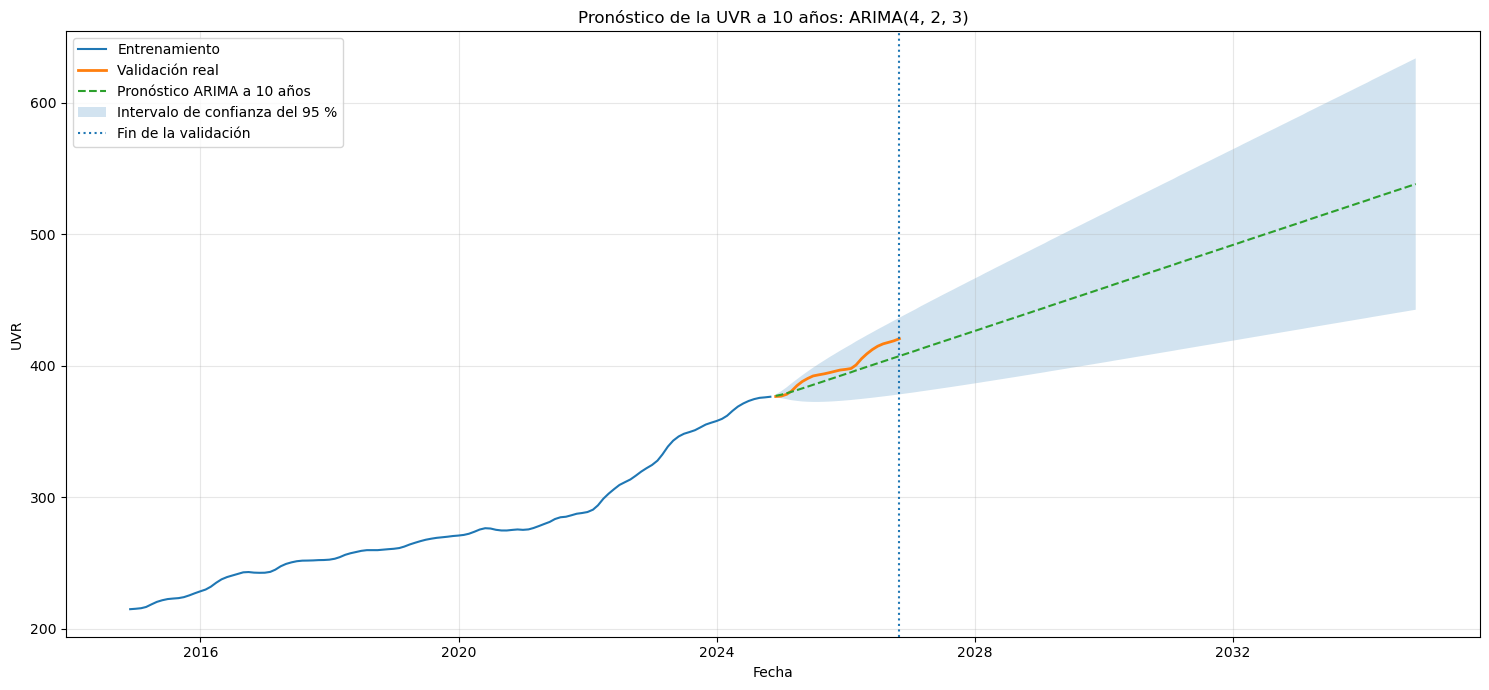

In [24]:
plt.figure(figsize=(15, 7))

plt.plot(
    serie_train.index,
    serie_train,
    label="Entrenamiento",
    linewidth=1.5
)

plt.plot(
    serie_test.index,
    serie_test,
    label="Validación real",
    linewidth=2
)

plt.plot(
    pronostico_10_anios.index,
    pronostico_10_anios["Pronóstico"],
    linestyle="--",
    label="Pronóstico ARIMA a 10 años"
)

plt.fill_between(
    pronostico_10_anios.index,
    pronostico_10_anios["Límite inferior"],
    pronostico_10_anios["Límite superior"],
    alpha=0.2,
    label="Intervalo de confianza del 95 %"
)

plt.axvline(
    serie_test.index.max(),
    linestyle=":",
    label="Fin de la validación"
)

plt.title(f"Pronóstico de la UVR a 10 años: ARIMA{orden}")
plt.xlabel("Fecha")
plt.ylabel("UVR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
ruta_excel_pronostico = "pronostico_uvr_arima.xlsx"
pronostico_10_anios.to_excel(ruta_excel_pronostico)
print(f"El pronóstico a 10 años se ha guardado correctamente en el archivo Excel: {ruta_excel_pronostico}")

El pronóstico a 10 años se ha guardado correctamente en el archivo Excel: pronostico_uvr_arima.xlsx
